# 1 · The sample: 53,000 non-financial firms in 123 countries, 2000-2020
**Sources:** Compustat Global (`g_funda`, 120 countries) and Compustat North America (`funda`) annual fundamentals, fiscal years 2000-2020, industrial format, consolidated, standardised statements.

**Construction** (`scripts/build_panel.py`, `firmpanel.clean`):
1. The two databases are combined. A firm-year present in both is kept once, from North America for US and Canadian firms and from Global otherwise.
2. Banks, insurers and other financials (GICS 40) and utilities (GICS 55) are excluded, because their balance sheets are not comparable.
3. Firm-years need positive total assets and sales. Size is converted to USD with World Bank average exchange rates.
4. Every ratio is winsorised at the 1st and 99th percentiles within each fiscal year.

The firm-level data is licensed and is not in this repository. Every table below is an aggregate, and cells with fewer than 20 firms are suppressed.

In [1]:
import sys, os, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd().parent; sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 2); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG, DATA = ROOT / "images", ROOT / "data"
from firmpanel import aggregate, regress
# licensed firm-level panel built by scripts/build_panel.py; it is never part of the repository
PANEL = pathlib.Path(os.environ.get("FIRMPANEL_DATA", ROOT / "private" / "panel.parquet"))
p = pd.read_parquet(PANEL)
REG_ORDER = ["North America", "Western Europe", "Japan", "Other developed Asia-Pacific", "China", "India", "OIC members", "Other emerging"]
from matplotlib.ticker import MaxNLocator
def int_years(*axes):
    for a in axes: a.xaxis.set_major_locator(MaxNLocator(integer=True)); a.set_xlabel("")
print(f"{len(p):,} firm-years, {p.gvkey.nunique():,} non-financial firms, {p['loc'].nunique()} countries, {p.fyear.min()}-{p.fyear.max()}")

607,799 firm-years, 52,792 non-financial firms, 123 countries, 2000-2020


In [2]:
cov = aggregate.summary(p, "loc", ["size"], stat="median", min_firms=30).rename(columns={"size": "median ln assets (USD m)"})
cov["median assets, USD m"] = np.exp(cov.pop("median ln assets (USD m)"))
cov["region"] = p.groupby("loc")["region"].first().reindex(cov.index)
cov = cov.sort_values("firms", ascending=False)
cov.to_csv(DATA / "coverage_by_country.csv")
print(f"{len(cov)} countries have at least 30 firms; together they hold {cov.firm_years.sum() / len(p):.1%} of firm-years")
cov.head(25)

70 countries have at least 30 firms; together they hold 99.1% of firm-years


,firms,firm_years,"median assets, USD m",region
loc,,,,
USA,11387,97555,245.95,North America
CHN,4704,58149,266.40,China
JPN,4261,58598,317.19,Japan
IND,3673,54194,22.66,India
GBR,2658,26430,86.23,Western Europe
CAN,2521,19830,108.99,North America
AUS,2319,24427,18.52,Other developed Asia-Pacific
TWN,2202,31040,91.68,Other developed Asia-Pacific
KOR,1998,19869,181.50,Other developed Asia-Pacific


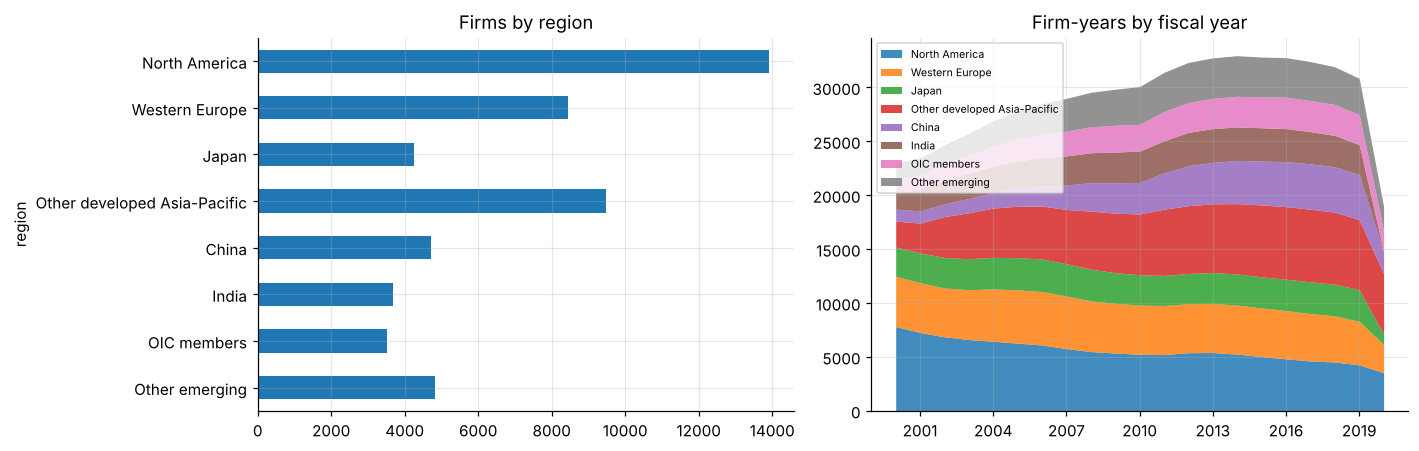

2020 is incomplete: many firms had not filed when the data was extracted (April 2021).


,firms,firm_years,countries,median_assets_usd_m
region,,,,
North America,13908,117385,2,212.53
Western Europe,8453,94514,18,135.99
Japan,4261,58598,1,317.19
Other developed Asia-Pacific,9465,113375,7,88.40
China,4704,58149,1,266.40
India,3673,54194,1,22.66
OIC members,3511,48831,26,73.91
Other emerging,4817,62753,67,90.23


In [3]:
reg = p.groupby("region").agg(firms=("gvkey", "nunique"), firm_years=("gvkey", "size"), countries=("loc", "nunique"),
                               median_assets_usd_m=("at_usd", "median")).reindex(REG_ORDER)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
reg["firms"].plot.barh(ax=ax[0], color="C0"); ax[0].invert_yaxis(); ax[0].set_title("Firms by region")
yr = p.groupby(["fyear", "region"]).size().unstack()[REG_ORDER]
yr.plot.area(ax=ax[1], stacked=True, alpha=0.85, lw=0); ax[1].set_title("Firm-years by fiscal year"); ax[1].legend(fontsize=7, loc="upper left"); int_years(ax[1])
plt.tight_layout(); plt.savefig(IMG / "coverage.png", bbox_inches="tight"); plt.show()
print("2020 is incomplete: many firms had not filed when the data was extracted (April 2021).")
reg

In [4]:
src = p.groupby(["region", "source"]).size().unstack(fill_value=0).reindex(REG_ORDER)
sec = p.groupby("gsector").size().rename(index={10: "Energy", 15: "Materials", 20: "Industrials", 25: "Consumer discretionary", 30: "Consumer staples",
                                                35: "Health care", 45: "Information technology", 50: "Communication services", 60: "Real estate"})
display(src); (100 * sec / sec.sum()).round(1).sort_values(ascending=False).rename("share of firm-years %")

source,Global,North America
region,,
North America,446,116939
Western Europe,92234,2280
Japan,58587,11
Other developed Asia-Pacific,111709,1666
China,54980,3169
India,54110,84
OIC members,48752,79
Other emerging,61621,1132


gsector
Industrials               22.2
Consumer discretionary    18.7
Information technology    16.5
Materials                 13.7
Health care                8.8
Consumer staples           8.6
Energy                     5.1
Communication services     4.9
Real estate                1.7
Name: share of firm-years %, dtype: float64

## Findings
* **A global panel of 607,799 firm-years:** 52,792 non-financial, non-utility firms in 123 countries over 2000-2020, built from Compustat Global (482,439 firm-years) and Compustat North America (125,360). 823 firms appear in both databases and are kept once.
* **Coverage is concentrated but broad:** 70 countries have at least 30 firms, and together they hold 99.1% of the firm-years. The largest are the USA (11,387 firms), China (4,704), Japan (4,261), India (3,673), the UK (2,658) and Canada (2,521). OIC member countries contribute 3,511 firms in 26 countries, led by Malaysia, Indonesia and Pakistan.
* **Firm size differs a lot by market:** median total assets are about USD 300m in Japan, 270m in China and 250m in the USA, but USD 23m in India and 19m in Australia, where many small resource and exploration companies are listed. Cross-country comparisons below therefore use ratios and medians, and the regressions use within-firm variation.
* **Composition changes over time:** Chinese and other Asian coverage grows strongly after 2005, and 2020 is incomplete because the data was extracted in April 2021. Trend charts stop in 2019, and same-firm comparisons are used where composition could mislead.